# 03 · Modelo de predicción de fallas

**Objetivo:** que el sistema **avise antes** de que una máquina falle, en lugar de enterarnos cuando ya se detuvo.

El modelo recibe las mediciones de un ciclo (temperaturas, velocidad, torque, desgaste, tipo de producto)
y devuelve una **probabilidad de falla**. Esa probabilidad se convierte en un **nivel de riesgo**
(Bajo / Medio / Alto) que n8n usará para mandar alertas.

**Dos retos de este problema:**
1. **Datos desbalanceados:** solo el 3.4 % de los ciclos son fallas. Un modelo que siempre diga "no falla" acierta el 96.6 % y no sirve para nada.
2. **Fuga de datos:** las columnas de *tipo de falla* (calor, potencia...) solo se conocen **después** de la falla. Si el modelo las usara, sería como darle las respuestas del examen. **No se usan.**

> Este notebook usa `data/processed/produccion_planta.csv`, generado por `01_exploracion.ipynb`.

## 0. Preparación

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve

from planta import config
from planta.data.guardado import guardar_csv_procesado
from planta.models.prediccion import (
    clasificar_riesgo,
    construir_tabla_predicciones,
    crear_random_forest,
    crear_regresion_logistica,
    dividir_datos,
    evaluar_modelo,
    importancia_variables,
    predecir_fuera_de_muestra,
    preparar_variables,
)

COLOR_RF = "#2a78d6"         # azul: Random Forest
COLOR_LOGISTICA = "#eb6834"  # naranja: Regresión logística
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#a3a29b", "axes.grid": True, "grid.color": "#e4e3df",
    "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titleweight": "bold",
    "font.size": 10,
})
pd.set_option("display.max_columns", 30)

## 1. Variables de entrada y variable a predecir

`preparar_variables()` agrega las 3 variables derivadas (diferencia de temperatura, potencia y esfuerzo)
y separa **X** (lo que el modelo ve) de **y** (lo que debe predecir: `falla_maquina`).

In [2]:
produccion = pd.read_csv(config.RUTA_CSV_PRODUCCION)
entradas, objetivo = preparar_variables(produccion)

print("Variables de entrada (X):", list(entradas.columns))
print(f"Variable a predecir (y): {objetivo.name}  ->  {objetivo.sum()} fallas de {len(objetivo)} ciclos ({objetivo.mean():.2%})")
entradas.head()

Variables de entrada (X): ['temperatura_aire_c', 'temperatura_proceso_c', 'velocidad_rotacion_rpm', 'torque_nm', 'desgaste_herramienta_min', 'diferencia_temperatura_c', 'potencia_w', 'esfuerzo_nm_min', 'tipo_producto']
Variable a predecir (y): falla_maquina  ->  339 fallas de 10000 ciclos (3.39%)


,temperatura_aire_c,temperatura_proceso_c,velocidad_rotacion_rpm,torque_nm,desgaste_herramienta_min,diferencia_temperatura_c,potencia_w,esfuerzo_nm_min,tipo_producto
0,24.95,35.45,1551,42.8,0,10.5,6951.6,0.0,M
1,25.05,35.55,1408,46.3,3,10.5,6826.7,138.9,L
2,24.95,35.35,1498,49.4,5,10.4,7749.4,247.0,L
3,25.05,35.45,1433,39.5,7,10.4,5927.5,276.5,L
4,25.05,35.55,1408,40.0,9,10.5,5897.8,360.0,L


## 2. Separar entrenamiento y prueba

- **Entrenamiento (80 %):** el modelo aprende con estos ciclos.
- **Prueba (20 %):** ciclos que el modelo **nunca vio**; sirven para medir qué tan bien funcionaría con datos nuevos.
- `stratify` mantiene el mismo porcentaje de fallas en ambos grupos, y `SEMILLA_REPRODUCIBLE` hace que la división sea siempre la misma.

In [3]:
entradas_ent, entradas_pru, objetivo_ent, objetivo_pru = dividir_datos(entradas, objetivo)
pd.DataFrame({
    "ciclos": [len(objetivo_ent), len(objetivo_pru)],
    "fallas": [objetivo_ent.sum(), objetivo_pru.sum()],
    "porcentaje_fallas": [round(objetivo_ent.mean() * 100, 2), round(objetivo_pru.mean() * 100, 2)],
}, index=["Entrenamiento", "Prueba"])

,ciclos,fallas,porcentaje_fallas
Entrenamiento,8000,271,3.39
Prueba,2000,68,3.40


## 3. Entrenar y comparar dos modelos

| Modelo | Cómo decide | Ventaja | Desventaja |
|---|---|---|---|
| **Regresión logística** | Suma ponderada de las variables → probabilidad | Simple, rápido, fácil de explicar | Solo capta relaciones "en línea recta" |
| **Random Forest** | 300 árboles de decisión que votan | Aprende reglas como "si potencia > 9 000 W..." y combinaciones | Más difícil de explicar en detalle |

Ambos usan `class_weight="balanced"`: equivocarse con una falla **pesa más** que con un ciclo normal.

**Cómo leer las métricas:**
- **Recall:** de las fallas reales, ¿cuántas detectó? (lo que más importa en mantenimiento)
- **Precisión:** de las alarmas que dio, ¿cuántas eran fallas reales? (si es baja, los operarios dejan de confiar)
- **F1:** equilibrio entre recall y precisión.
- **PR-AUC:** calidad general del modelo en datos desbalanceados (1 = perfecto).

In [4]:
modelos = {
    "Regresión logística": crear_regresion_logistica().fit(entradas_ent, objetivo_ent),
    "Random Forest": crear_random_forest().fit(entradas_ent, objetivo_ent),
}
comparacion = pd.DataFrame({nombre: evaluar_modelo(modelo, entradas_pru, objetivo_pru)
                            for nombre, modelo in modelos.items()})
comparacion["Modelo 'siempre no falla'"] = {
    "exactitud": round((objetivo_pru == 0).mean(), 4), "precision": 0.0, "recall": 0.0, "f1": 0.0,
    "pr_auc": round(objetivo_pru.mean(), 4), "verdaderos_negativos": int((objetivo_pru == 0).sum()),
    "falsos_positivos": 0, "falsos_negativos": int(objetivo_pru.sum()), "verdaderos_positivos": 0,
}
comparacion

,Regresión logística,Random Forest,Modelo 'siempre no falla'
exactitud,0.8585,0.9925,0.966
precision,0.1791,0.9492,0.000
recall,0.8824,0.8235,0.000
f1,0.2978,0.8819,0.000
pr_auc,0.4297,0.8697,0.034
verdaderos_negativos,1657.0000,1929.0000,1932.000
falsos_positivos,275.0000,3.0000,0.000
falsos_negativos,8.0000,12.0000,68.000
verdaderos_positivos,60.0000,56.0000,0.000


**Conclusión: el Random Forest es claramente mejor.**

- **La exactitud engaña:** el modelo "siempre no falla" tiene **96.6 %** de exactitud y no detecta **ninguna** falla. La regresión logística tiene *menos* exactitud (85.85 %) y aun así es más útil.
- **Regresión logística:** detecta el **88.24 %** de las fallas, pero solo el **17.91 %** de sus alarmas son reales (275 falsas alarmas). En una planta, los operarios dejarían de hacerle caso.
- **Random Forest:** detecta el **82.35 %** de las fallas y el **94.92 %** de sus alarmas son reales (solo **3** falsas alarmas). Su F1 (0.88) y su PR-AUC (0.87) son más del doble que los de la logística.

**¿Por qué?** En el EDA vimos que las fallas ocurren en los **extremos** (potencia muy baja *o* muy alta). La regresión logística solo puede trazar una frontera "en línea recta"; los árboles aprenden reglas del tipo "si potencia > 9 000 W...".

### Matriz de confusión
Cada cuadro cuenta ciclos de prueba según **lo que pasó realmente** (filas) y **lo que predijo el modelo** (columnas).

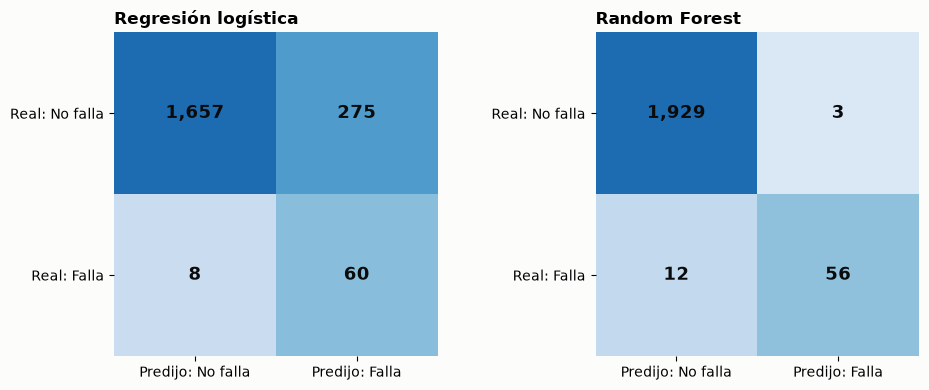

In [5]:
figura, ejes = plt.subplots(1, 2, figsize=(10, 4))
etiquetas = ["No falla", "Falla"]
for eje, (nombre, modelo) in zip(ejes, modelos.items()):
    m = comparacion[nombre]
    matriz = np.array([[m["verdaderos_negativos"], m["falsos_positivos"]],
                       [m["falsos_negativos"], m["verdaderos_positivos"]]]).astype(int)
    eje.imshow(np.log1p(matriz), cmap="Blues", vmin=0, vmax=np.log1p(matriz.max()) * 1.3)
    for fila in range(2):
        for columna in range(2):
            eje.text(columna, fila, f"{matriz[fila, columna]:,}", ha="center", va="center",
                     fontsize=13, fontweight="bold", color="#0b0b0b")
    eje.set_xticks([0, 1], [f"Predijo: {e}" for e in etiquetas])
    eje.set_yticks([0, 1], [f"Real: {e}" for e in etiquetas])
    eje.set_title(nombre)
    eje.grid(False)
    for borde in eje.spines.values():
        borde.set_visible(False)
figura.tight_layout()
plt.show()

**Conclusión:** en 2 000 ciclos de prueba con 68 fallas:

- **Regresión logística:** acierta 60 fallas y se le escapan 8, pero da **275 falsas alarmas**.
- **Random Forest:** acierta 56 fallas y se le escapan 12, con solo **3 falsas alarmas**.

El Random Forest cambia 4 fallas detectadas por **272 falsas alarmas menos**. En mantenimiento, un sistema con pocas falsas alarmas es uno en el que la gente **confía y actúa**.

### Curva de precisión y recall
Cada punto de la curva es un **umbral distinto**. Un modelo ideal estaría pegado a la esquina superior derecha
(detecta todas las fallas sin falsas alarmas).

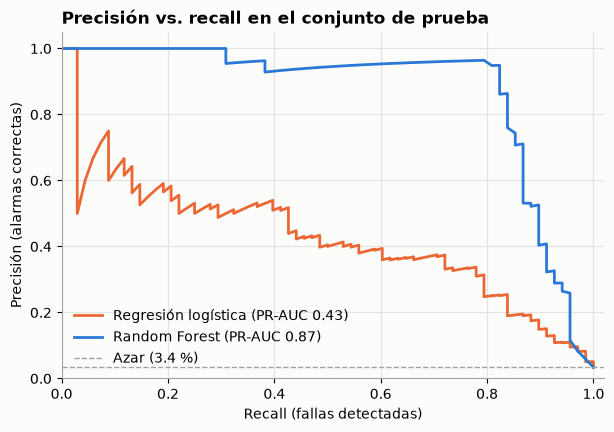

In [6]:
figura, eje = plt.subplots(figsize=(7, 4.5))
for (nombre, modelo), color in zip(modelos.items(), [COLOR_LOGISTICA, COLOR_RF]):
    probabilidades = modelo.predict_proba(entradas_pru)[:, 1]
    precision, recall, _ = precision_recall_curve(objetivo_pru, probabilidades)
    eje.plot(recall, precision, color=color, linewidth=2,
             label=f"{nombre} (PR-AUC {comparacion.loc['pr_auc', nombre]:.2f})")
eje.axhline(objetivo_pru.mean(), color="#a3a29b", linestyle="--", linewidth=1, label="Azar (3.4 %)")
eje.set_xlabel("Recall (fallas detectadas)")
eje.set_ylabel("Precisión (alarmas correctas)")
eje.set_xlim(0, 1.02)
eje.set_ylim(0, 1.05)
eje.set_title("Precisión vs. recall en el conjunto de prueba")
eje.legend(loc="lower left", frameon=False)
plt.show()

## 4. ¿Qué variables usa más el Random Forest?
La **importancia** indica cuánto ayudó cada variable a separar fallas de no fallas (suman 1).

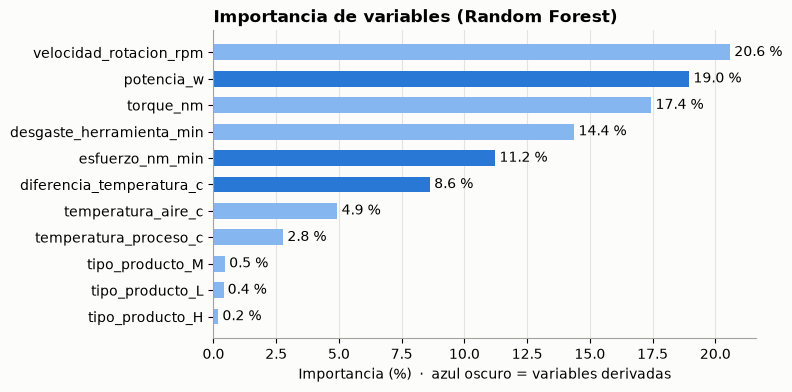

In [7]:
importancias = importancia_variables(modelos["Random Forest"])
figura, eje = plt.subplots(figsize=(7, 4))
orden = importancias.sort_values()
colores = [COLOR_RF if nombre in ("diferencia_temperatura_c", "potencia_w", "esfuerzo_nm_min") else "#86b6ef"
           for nombre in orden.index]
barras = eje.barh(orden.index, orden.values * 100, color=colores, height=0.6)
eje.bar_label(barras, fmt="%.1f %%", padding=3)
eje.set_xlabel("Importancia (%)  ·  azul oscuro = variables derivadas")
eje.set_title("Importancia de variables (Random Forest)")
eje.grid(axis="y", visible=False)
plt.show()

**Conclusión:**

- Las variables más usadas son **velocidad (20.6 %)**, **potencia (19.0 %)** y **torque (17.4 %)**: las tres relacionadas con las fallas de potencia y sobreesfuerzo.
- Las **3 variables derivadas** (azul oscuro) suman **38.8 %** de la importancia, y la potencia es la segunda más importante. **Crearlas valió la pena.**
- El **tipo de producto** casi no se usa (1.1 % entre los tres), porque su efecto ya está incluido en el esfuerzo.
- Las temperaturas por separado pesan poco; lo que importa es su **diferencia**, igual que vimos con M03 en el notebook 02.

## 5. Predicciones honestas para toda la planta

Para el dashboard y las alertas necesitamos una probabilidad para **los 10 000 ciclos**.
Si usáramos el modelo entrenado con esos mismos ciclos, "ya se sabría las respuestas".

`predecir_fuera_de_muestra()` usa **validación cruzada de 5 partes**: entrena con 4 partes y predice la quinta,
y repite hasta cubrirlas todas. Así **cada ciclo es predicho por un modelo que nunca lo vio**.

In [8]:
probabilidades = predecir_fuera_de_muestra(crear_random_forest(), entradas, objetivo)
predicciones = construir_tabla_predicciones(produccion, probabilidades)
predicciones.head()

,id_registro,id_maquina,fecha_hora,turno,tipo_producto,probabilidad_falla,nivel_riesgo,falla_real
0,1,M01,2026-09-01T06:00:00,Mañana,M,0.0000,Bajo,0
1,2,M01,2026-09-01T06:30:00,Mañana,L,0.0033,Bajo,0
2,3,M01,2026-09-01T07:00:00,Mañana,L,0.0000,Bajo,0
3,4,M01,2026-09-01T07:30:00,Mañana,L,0.0000,Bajo,0
4,5,M01,2026-09-01T08:00:00,Mañana,L,0.0000,Bajo,0


### Elegir el umbral de alerta
El umbral decide desde qué probabilidad se considera "falla". Bajarlo detecta más fallas, **pero con más falsas alarmas**.

In [9]:
filas = []
for umbral in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    alarma = probabilidades >= umbral
    detectadas = int((alarma & (objetivo == 1)).sum())
    falsas = int((alarma & (objetivo == 0)).sum())
    filas.append({"umbral": umbral, "fallas_detectadas": detectadas, "recall": round(detectadas / objetivo.sum(), 3),
                  "falsas_alarmas": falsas, "precision": round(detectadas / max(alarma.sum(), 1), 3)})
pd.DataFrame(filas).set_index("umbral")

,fallas_detectadas,recall,falsas_alarmas,precision
umbral,,,,
0.2,297,0.876,237,0.556
0.3,290,0.855,125,0.699
0.4,287,0.847,61,0.825
0.5,284,0.838,34,0.893
0.6,272,0.802,12,0.958
0.7,252,0.743,6,0.977


**Conclusión:** se mantiene el umbral de alerta en **0.6** (riesgo Alto).

- Con **0.6**, el modelo detecta **272 de 339 fallas (80.2 %)** y da solo **12 falsas alarmas** en 10 000 ciclos: el **95.8 %** de las alertas son reales.
- Bajar a **0.3** solo agrega **18 fallas** detectadas, pero multiplica las falsas alarmas por 10 (125).
- Subir a **0.7** reduce las falsas alarmas a 6, pero se pierden **20 fallas** más.

En 0.6 está el mejor equilibrio para **alertas que interrumpen a una persona** (Telegram en el Día 4). El nivel **Medio** sirve como zona de vigilancia en el dashboard, sin mandar alertas.

### Niveles de riesgo
Con los umbrales de `config.py`: **Bajo** (< 30 %), **Medio** (30 % – 60 %) y **Alto** (≥ 60 %).

In [10]:
niveles = (predicciones.groupby("nivel_riesgo")["falla_real"]
           .agg(ciclos="size", fallas_reales="sum")
           .reindex(["Bajo", "Medio", "Alto"]))
niveles["porcentaje_que_fallo"] = (niveles["fallas_reales"] / niveles["ciclos"] * 100).round(1)
niveles["porcentaje_de_todas_las_fallas"] = (niveles["fallas_reales"] / objetivo.sum() * 100).round(1)
niveles

,ciclos,fallas_reales,porcentaje_que_fallo,porcentaje_de_todas_las_fallas
nivel_riesgo,,,,
Bajo,9585,49,0.5,14.5
Medio,131,18,13.7,5.3
Alto,284,272,95.8,80.2


In [11]:
por_maquina = pd.crosstab(predicciones["id_maquina"], predicciones["nivel_riesgo"])[["Bajo", "Medio", "Alto"]]
por_maquina["fallas_reales"] = predicciones.groupby("id_maquina")["falla_real"].sum()
por_maquina

nivel_riesgo,Bajo,Medio,Alto,fallas_reales
id_maquina,,,,
M01,1938,17,42,52
M02,1961,32,45,53
M03,1785,44,136,150
M04,1973,22,34,46
M05,1928,16,27,38


**Conclusión:**

| Nivel | Qué significa en la práctica |
|---|---|
| **Alto** (284 ciclos) | El **95.8 %** terminó en falla. Captura el **80.2 %** de todas las fallas → **alerta inmediata** |
| **Medio** (131 ciclos) | 1 de cada 7 terminó en falla → **vigilar** en el dashboard |
| **Bajo** (9 585 ciclos) | Solo el **0.5 %** falló → operación normal |

**Por máquina:** M03 tiene **136 ciclos en riesgo Alto**, más del triple que cualquier otra (27–45). El modelo encontró por su cuenta el mismo problema que vimos en el OEE.

## 6. ¿Qué fallas no logra anticipar?

In [12]:
tipos_falla = ["falla_desgaste_herramienta", "falla_disipacion_calor", "falla_potencia",
               "falla_sobreesfuerzo", "falla_aleatoria"]
fallas = produccion[produccion["falla_maquina"] == 1].assign(nivel_riesgo=predicciones["nivel_riesgo"])
fallas["sin_tipo_registrado"] = (fallas[tipos_falla].sum(axis=1) == 0).astype(int)
fallas.groupby("nivel_riesgo")[tipos_falla + ["sin_tipo_registrado"]].sum().reindex(["Bajo", "Medio", "Alto"])

,falla_desgaste_herramienta,falla_disipacion_calor,falla_potencia,falla_sobreesfuerzo,falla_aleatoria,sin_tipo_registrado
nivel_riesgo,,,,,,
Bajo,40,0,0,0,0,9
Medio,4,7,5,3,1,0
Alto,2,108,90,95,0,0


**Conclusión: el modelo anticipa casi todas las fallas que tienen una causa física medible.**

- **Calor, potencia y sobreesfuerzo:** ninguna quedó en riesgo Bajo. Todas están en Medio o Alto.
- **Desgaste de herramienta:** **40 de 46** quedaron en Bajo. En este dataset ocurren en un minuto **al azar** entre ~200 y 240 min de desgaste, así que ningún modelo puede saber el momento exacto.
- **Sin tipo registrado:** las **9** fallas sin causa marcada quedaron en Bajo (son las inconsistencias del dataset que vimos en el EDA).

**La recomendación para las fallas de desgaste no es un mejor modelo, sino mantenimiento preventivo:** *cambiar la herramienta al llegar a ~200 min*. La IA y el conocimiento del proceso se complementan.

## 7. Guardar `predicciones_fallas.csv`
Una fila por ciclo con su probabilidad y nivel de riesgo. **n8n** lo leerá para mandar alertas de riesgo **Alto**
y **Power BI** lo usará en el dashboard. La columna `falla_real` permite comparar predicción y realidad.

In [13]:
ruta = guardar_csv_procesado(predicciones, config.RUTA_CSV_PREDICCIONES)
print("Guardado en:", ruta.relative_to(config.RAIZ_PROYECTO))
print(f"{len(predicciones)} filas x {predicciones.shape[1]} columnas")
print(list(predicciones.columns))
print(predicciones["nivel_riesgo"].value_counts().reindex(["Bajo", "Medio", "Alto"]).to_dict())

Guardado en: data\processed\predicciones_fallas.csv
10000 filas x 8 columnas
['id_registro', 'id_maquina', 'fecha_hora', 'turno', 'tipo_producto', 'probabilidad_falla', 'nivel_riesgo', 'falla_real']
{'Bajo': 9585, 'Medio': 131, 'Alto': 284}


## 8. Conclusiones generales

1. **El Random Forest es el modelo elegido:** en datos que no vio, detecta el **82 %** de las fallas con un **95 %** de alarmas correctas. La regresión logística detecta un poco más, pero con 90 veces más falsas alarmas.
2. **Los niveles de riesgo funcionan:** el nivel **Alto** captura el **80 %** de las fallas y el **96 %** de sus alertas son reales. Es la base de las alertas de n8n.
3. **Las variables derivadas aportan:** potencia, esfuerzo y diferencia de temperatura suman casi el **39 %** de la importancia.
4. **El modelo confirma a M03 como la máquina problema**, sin que nadie se lo dijera.
5. **Las fallas por desgaste no se predicen bien** porque ocurren al azar; se atacan con mantenimiento preventivo por tiempo de uso.

### Limitaciones (para decirlas antes de que las pregunten)
- **El dataset es sintético:** las fallas siguen reglas fijas, por eso el modelo sale tan bueno. Con sensores reales las métricas serían más bajas y habría que reentrenar.
- **La división fue aleatoria, no por tiempo.** En producción, lo correcto sería entrenar con el pasado y evaluar con el futuro, y volver a entrenar cada cierto tiempo.
- **Los supuestos del OEE y los umbrales** están en `config.py` y deben ajustarse con datos y criterio de la planta real.

**Siguiente paso (Día 4):** n8n leerá `predicciones_fallas.csv` y enviará una alerta por cada ciclo en riesgo **Alto**.